In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler 
from imblearn.under_sampling import RandomUnderSampler
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, auc, roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV,cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from category_encoders import OneHotEncoder
import pickle
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.metrics import mean_squared_error,accuracy_score

Read the data into a Dataframe

In [2]:
df= pd.read_csv("credit_risk.csv")

In [3]:
df.shape

(32581, 12)

Our data consist of 32,581 rows and 12 columns

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              32581 non-null  int64  
 1   Age             32581 non-null  int64  
 2   Income          32581 non-null  int64  
 3   Home            32581 non-null  object 
 4   Emp_length      31686 non-null  float64
 5   Intent          32581 non-null  object 
 6   Amount          32581 non-null  int64  
 7   Rate            29465 non-null  float64
 8   Status          32581 non-null  int64  
 9   Percent_income  32581 non-null  float64
 10  Default         32581 non-null  object 
 11  Cred_length     32581 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 3.0+ MB


Set the ID columns as index of the Dataframe

As shown above, some of the columns in our data such as Emp_length and Rate have missing values

In [5]:
# set the ID columns as index of the data
df=df.set_index("Id")
df.dropna(inplace=True)

In [6]:
df.head()

,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
Id,,,,,,,,,,,
0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


In the Default column, replace Y with 1 and N with 0

In [7]:
df["Default"]=df["Default"].replace({"Y":1, "N":0}) 
df.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_3680\1760250455.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Default"]=df["Default"].replace({"Y":1, "N":0})


,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
Id,,,,,,,,,,,
0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,1,3
1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,0,2
2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,0,3
3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,0,2
4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,1,4


Exploratory Data Analysis

In [8]:
df["Age"].describe()

count    28638.000000
mean        27.727216
std          6.310441
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        144.000000
Name: Age, dtype: float64

In [9]:
Age_mean=df["Age"].mean()
Age_median=df["Age"].median()
print(Age_mean)
print(Age_median)

27.727215587680703
26.0


Plot the histogram of the age distribution showing the mean and median measures of central tendency 

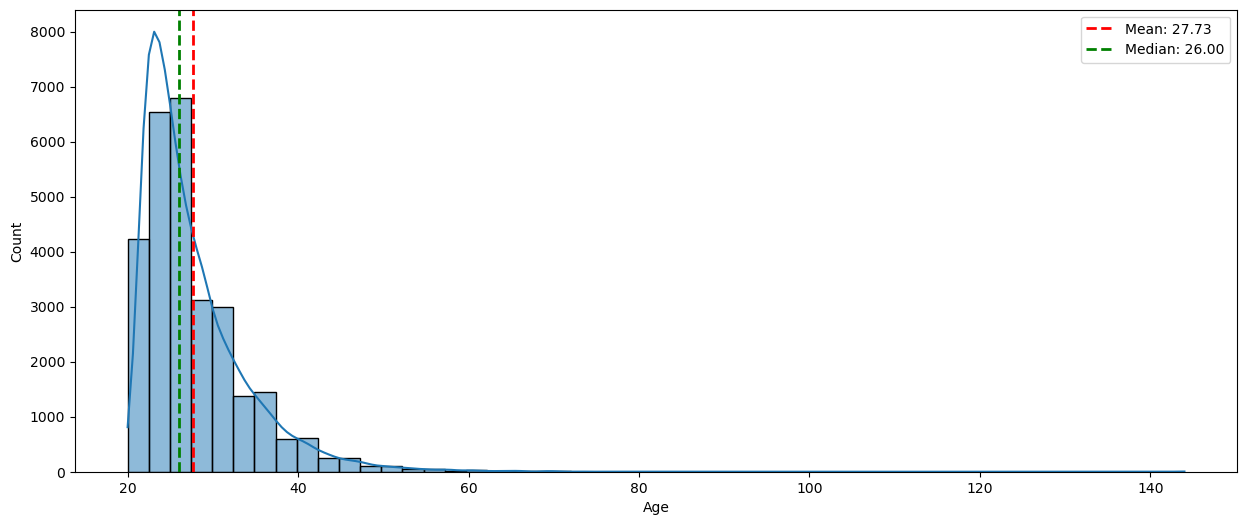

In [10]:
fig,ax=plt.subplots(figsize=(15,6))
sns.histplot(df["Age"], bins=50, kde=True)
plt.axvline(Age_mean, color="r", linestyle="--", linewidth=2, label=f"Mean: {Age_mean:.2f}")
plt.axvline(Age_median, color="g", linestyle="--", linewidth=2, label=f"Median: {Age_median:.2f}")
plt.legend()
plt.show()

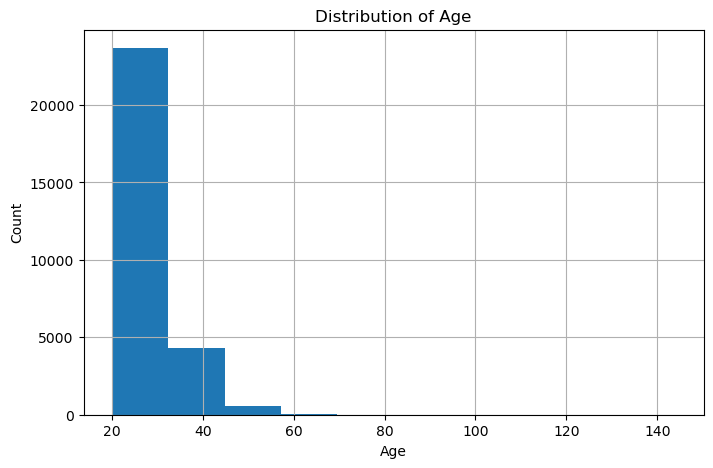

In [11]:
fig,ax=plt.subplots(figsize=(8,5))
df["Age"].hist()
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Distribution of Age");

Create a Boxplot of the Age Distribution

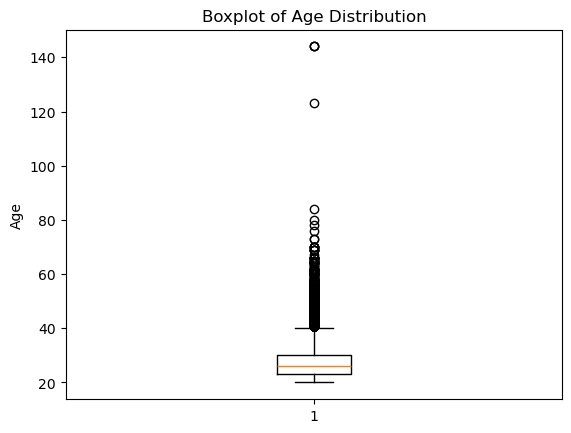

In [12]:
plt.boxplot(df["Age"])
plt.ylabel("Age")
plt.title("Boxplot of Age Distribution");

Following the exploration of the Age column the difference between the mean and median measures of central tendency with the mean being greater than the median thereby suggesting the presence of outliers in the Age column. This is further confirmed by the histogram and boxplot with the former showing that the Age data is heavily skewed to the right.

In addition to the presence of outliers in the Age column, another key insight is the fact that majority of the borrowers fall between the ages of 20 and 45 years.

Exploratory analysis of the Income column

In [13]:
df["Income"].describe().apply("{0:,.0f}".format)

count       28,638
mean        66,649
std         62,356
min          4,000
25%         39,480
50%         55,956
75%         80,000
max      6,000,000
Name: Income, dtype: object

In [14]:
Income_mean=df["Income"].mean()
Income_median=df["Income"].median()
print(f"Income_mean: {Income_mean}")
print(f"Income_median: {Income_median}")

Income_mean: 66649.37188351141
Income_median: 55956.0


Plot the histogram of the age distribution showing the mean and median measures of central tendency

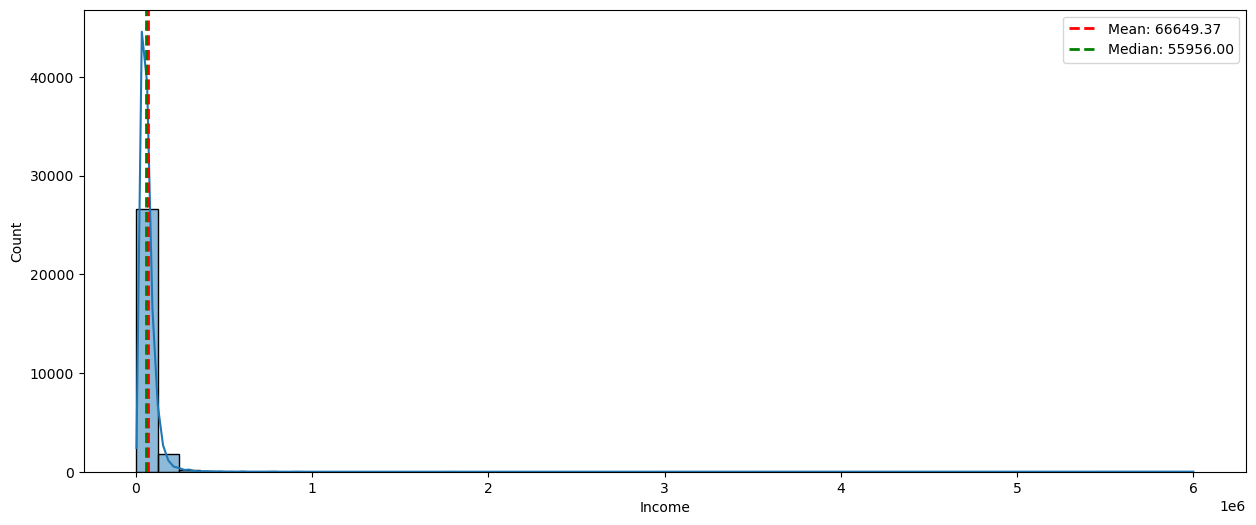

In [15]:
fig,ax=plt.subplots(figsize=(15,6))
sns.histplot(df["Income"], bins=50, kde=True)
plt.axvline(Income_mean, color="r", linestyle="--", linewidth=2, label=f"Mean: {Income_mean:.2f}")
plt.axvline(Income_median, color="g", linestyle="--", linewidth=2, label=f"Median: {Income_median:.2f}")
plt.legend()
plt.show()

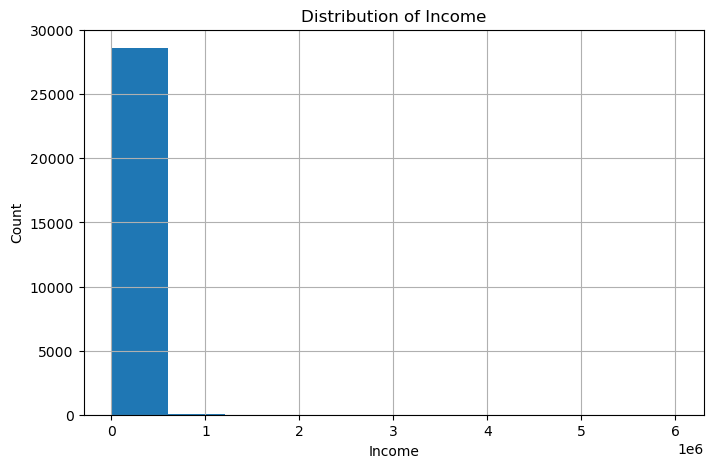

In [16]:
fig,ax=plt.subplots(figsize=(8,5))
df["Income"].hist()
plt.xlabel("Income")
plt.ylabel("Count")
plt.title("Distribution of Income");

Create Boxplot of the Income Distribution to  check for possible outliers

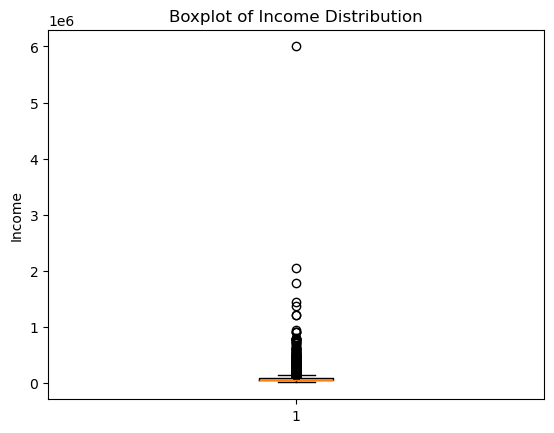

In [17]:
plt.boxplot(df["Income"])
plt.ylabel("Income")
plt.title("Boxplot of Income Distribution");

In [18]:
q2_income=df["Income"].quantile(.9)
print(q2_income)

112000.0


In [19]:
q2_age=df["Age"].quantile(.99)
print(q2_age)

50.0


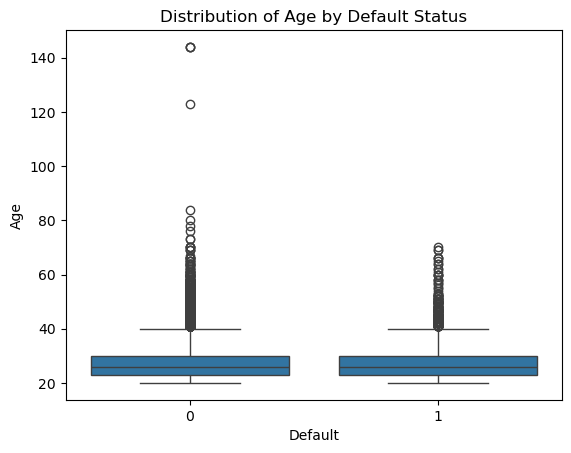

In [20]:
sns.boxplot(x="Default", y="Age", data=df)
plt.xlabel("Default")
plt.ylabel("Age")
plt.title("Distribution of Age by Default Status");

In [21]:
mask=df["Default"]==1
df_defaulter=df[mask]
df_defaulter.describe()

,Age,Income,Emp_length,Amount,Rate,Status,Percent_income,Default,Cred_length
count,5103.000000,5.103000e+03,5103.000000,5103.000000,5103.000000,5103.000000,5103.000000,5103.0,5103.000000
mean,27.832451,6.628663e+04,4.540074,10204.565942,14.509195,0.377621,0.177752,1.0,5.866549
std,6.166413,5.784887e+04,4.290270,6879.356908,1.730238,0.484840,0.109231,0.0,4.030025
min,20.000000,4.000000e+03,0.000000,750.000000,10.280000,0.000000,0.000000,1.0,2.000000
25%,23.000000,3.700000e+04,2.000000,5000.000000,13.230000,0.000000,0.090000,1.0,3.000000
50%,26.000000,5.499600e+04,4.000000,8500.000000,14.260000,0.000000,0.160000,1.0,4.000000
75%,30.000000,7.855200e+04,7.000000,14500.000000,15.600000,1.000000,0.240000,1.0,8.000000
max,70.000000,2.039784e+06,123.000000,35000.000000,23.220000,1.000000,0.700000,1.0,30.000000


In [22]:
q_upper=df["Age"].quantile(0.95)
print(q_upper)

40.0


In [23]:
df["Home"].value_counts(normalize=True)

Home
RENT        0.508101
MORTGAGE    0.412075
OWN         0.076542
OTHER       0.003282
Name: proportion, dtype: float64

Text(0.5, 1.0, 'Home Ownership')

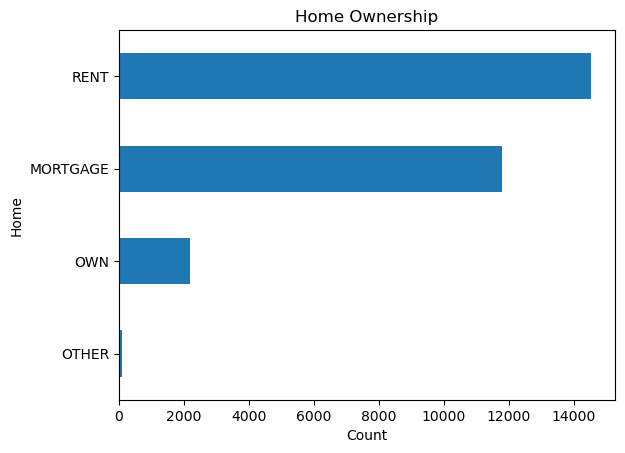

In [24]:
df["Home"].value_counts(ascending=True).plot(kind="barh");
plt.xlabel("Count")
plt.title("Home Ownership")

In [25]:
df["Intent"].value_counts(normalize=True)

Intent
EDUCATION            0.199176
MEDICAL              0.184824
VENTURE              0.174628
PERSONAL             0.170298
DEBTCONSOLIDATION    0.159404
HOMEIMPROVEMENT      0.111670
Name: proportion, dtype: float64

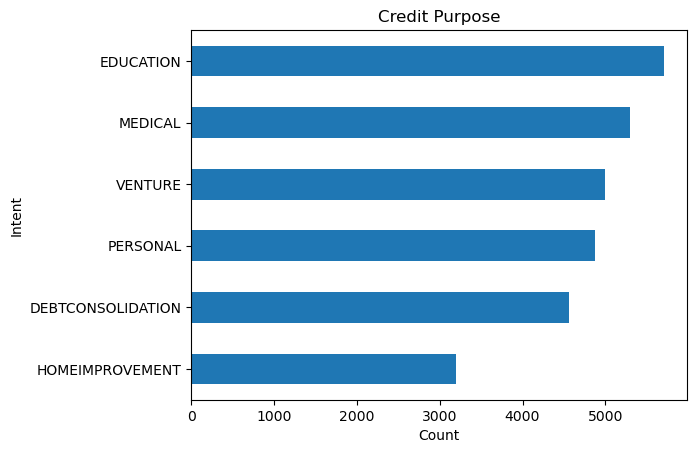

In [26]:
df["Intent"].value_counts(ascending=True).plot(kind="barh")
plt.xlabel("Count")
plt.title("Credit Purpose");

In [27]:
df["Default"].value_counts(normalize=True)

Default
0    0.82181
1    0.17819
Name: proportion, dtype: float64

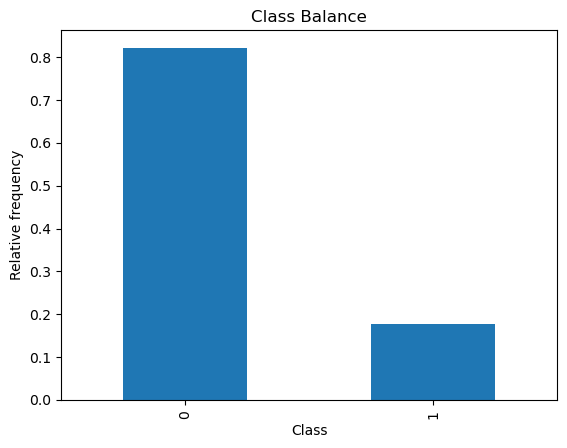

In [28]:
df["Default"].value_counts(normalize=True).plot(kind="bar", xlabel="Class", ylabel="Relative frequency", title="Class Balance");

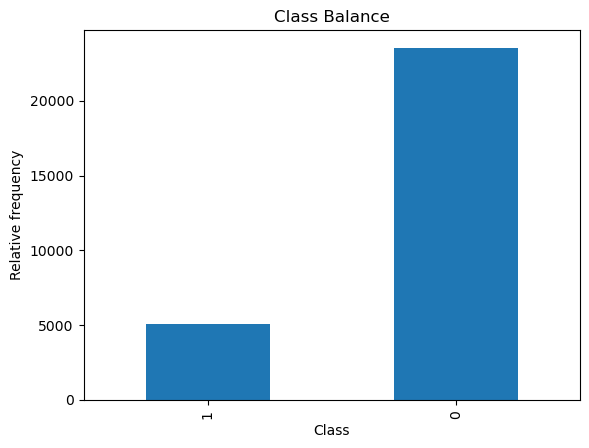

In [29]:
df["Default"].value_counts(ascending=True).plot(kind="bar", xlabel="Class", ylabel="Relative frequency", title="Class Balance");

The Bar chat shows that we have Class imbalance with 82% of the borrowers in the non-default class and 17% in the default class

In [30]:
corr=df.select_dtypes("number").corr()
#sns.heatmap(corr);
corr.style.background_gradient(axis=None)

,Age,Income,Emp_length,Amount,Rate,Status,Percent_income,Default,Cred_length
Age,1.000000,0.178899,0.165787,0.054172,0.011019,-0.023333,-0.041065,0.007765,0.859544
Income,0.178899,1.000000,0.136825,0.265879,-0.001381,-0.139938,-0.251511,-0.002709,0.117076
Emp_length,0.165787,0.136825,1.000000,0.110759,-0.056405,-0.082638,-0.055167,-0.027863,0.146336
Amount,0.054172,0.265879,0.110759,1.000000,0.145904,0.113550,0.577399,0.040320,0.045294
Rate,0.011019,-0.001381,-0.056405,0.145904,1.000000,0.339350,0.123500,0.500254,0.015371
Status,-0.023333,-0.139938,-0.082638,0.113550,0.339350,1.000000,0.379689,0.182019,-0.015649
Percent_income,-0.041065,-0.251511,-0.055167,0.577399,0.123500,0.379689,1.000000,0.036170,-0.030080
Default,0.007765,-0.002709,-0.027863,0.040320,0.500254,0.182019,0.036170,1.000000,0.008396
Cred_length,0.859544,0.117076,0.146336,0.045294,0.015371,-0.015649,-0.030080,0.008396,1.000000


Remove outliers from Age and Income

In [31]:
mask=(df["Income"]<q2_income) & (df["Age"]<q2_age)
df=df[mask]

In [32]:
df["Income"].describe()

count     25514.000000
mean      55249.260994
std       22848.410126
min        4000.000000
25%       37127.000000
50%       52000.000000
75%       70800.000000
max      111996.000000
Name: Income, dtype: float64

In [33]:
Income_mean=df["Income"].mean()
Income_median=df["Income"].median()
print(f"Income_mean: {Income_mean}")
print(f"Income_median: {Income_median}")

Income_mean: 55249.2609939641
Income_median: 52000.0


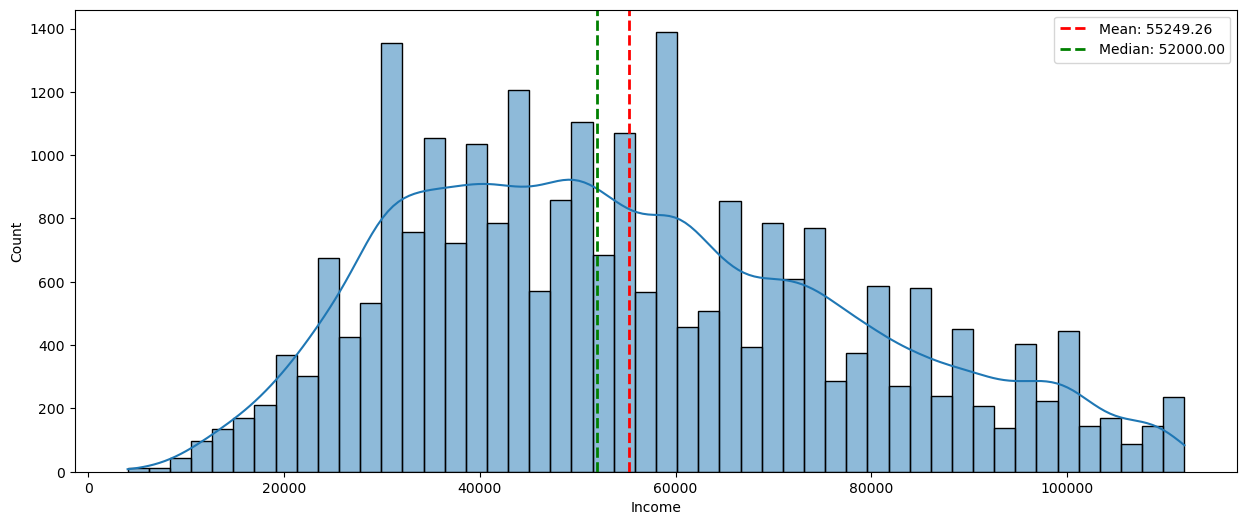

In [34]:
fig,ax=plt.subplots(figsize=(15,6))
sns.histplot(df["Income"], bins=50, kde=True)
plt.axvline(Income_mean, color="r", linestyle="--", linewidth=2, label=f"Mean: {Income_mean:.2f}")
plt.axvline(Income_median, color="g", linestyle="--", linewidth=2, label=f"Median: {Income_median:.2f}")
plt.legend()
plt.show()

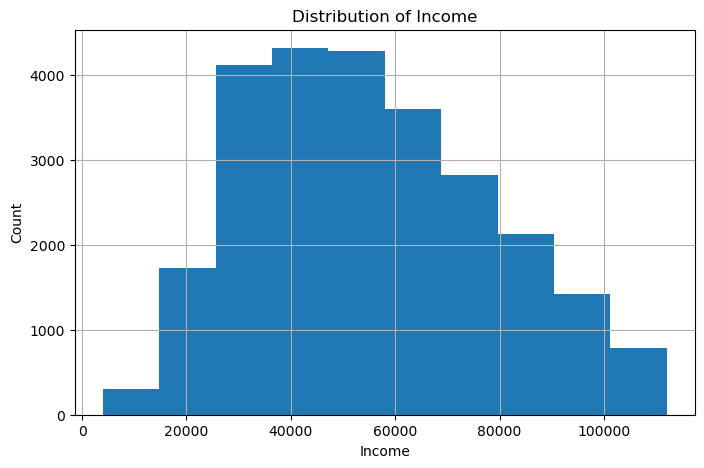

In [35]:
fig,ax=plt.subplots(figsize=(8,5))
df["Income"].hist()
plt.xlabel("Income")
plt.ylabel("Count")
plt.title("Distribution of Income");

SUMMARY OF THE INSIGHTS FROM OUR EXPLORATORY DATA ANALYSIS (EDA)
1. Our data is imbalanced. This we need to address in our data preparation
2. Many of our features have missing values that we'll need to impute and the best imputation strategy would be the median since the features are highly skewed
3. We also have autocorrelation issues, which means we should steer clear of linear models and try tree-based models instead.

SPLIT THE DATA

In [36]:
target="Default"
X=df.drop(columns=target)
y=df[target]

In [37]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
under_sampler=RandomUnderSampler(random_state=42)

X_train_under, y_train_under=under_sampler.fit_resample(X_train, y_train)

In [39]:
print(X_train_under.shape)
print(y_train_under.shape)

(7274, 10)
(7274,)


In [40]:
X_train_under.head()

,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Cred_length
Id,,,,,,,,,,
8744,25,60000,MORTGAGE,9.0,DEBTCONSOLIDATION,9600,6.03,0,0.16,3
11736,22,80000,RENT,6.0,PERSONAL,10000,8.49,0,0.13,4
8513,21,34000,RENT,5.0,DEBTCONSOLIDATION,7800,13.79,1,0.23,2
30464,44,29088,RENT,3.0,DEBTCONSOLIDATION,7200,11.71,0,0.25,17
23351,27,62000,MORTGAGE,2.0,HOMEIMPROVEMENT,5000,5.42,0,0.08,5


In [41]:
over_sampler=RandomOverSampler(random_state=42)
X_train_over,y_train_over=over_sampler.fit_resample(X_train, y_train)

In [42]:
print(X_train_over.shape)

(33548, 10)


In [43]:
#baseline

acc_baseline=y_train.value_counts(normalize=True).max()

print("Bseline accuracy:", round(acc_baseline, 4))

Bseline accuracy: 0.8218


In [44]:
# Fit on X_train, y_train

model_reg= make_pipeline(OneHotEncoder(use_cat_names=True), DecisionTreeClassifier(random_state=42))
model_reg.fit(X_train, y_train)

#Fit on X_train_under, y_train_under

model_under= make_pipeline(OneHotEncoder(use_cat_names=True),DecisionTreeClassifier(random_state=42))
model_under.fit(X_train_under, y_train_under)

#Fit on X_train_over, y_train_over

model_over= make_pipeline(OneHotEncoder(use_cat_names=True),DecisionTreeClassifier(random_state=42))
model_over.fit(X_train_over, y_train_over)

,steps,"[('onehotencoder', ...), ('decisiontreeclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,verbose,0
,cols,"['Home', 'Intent']"
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,use_cat_names,True


In [45]:
for m in [model_reg, model_under, model_over]:
    acc_train=m.score(X_train, y_train)
    acc_test=m.score(X_test, y_test)
    probabilities=m.predict_proba(X_test)[:,1]
    fpr,tpr,thresholds=roc_curve(y_test, probabilities)
    roc_auc= auc(fpr, tpr)
    print("Training_accuracy:", round(acc_train, 4))
    print("Test_accuracy:", round(acc_test, 4))
    print("Area under the curve(AUC):", round(roc_auc, 2))

 


Training_accuracy: 0.9992
Test_accuracy: 0.8258
Area under the curve(AUC): 0.7
Training_accuracy: 0.8891
Test_accuracy: 0.8168
Area under the curve(AUC): 0.81
Training_accuracy: 0.9992
Test_accuracy: 0.8154
Area under the curve(AUC): 0.68


Random under sampling of the training data seems to give the best result with ROC_AUC of 0.81

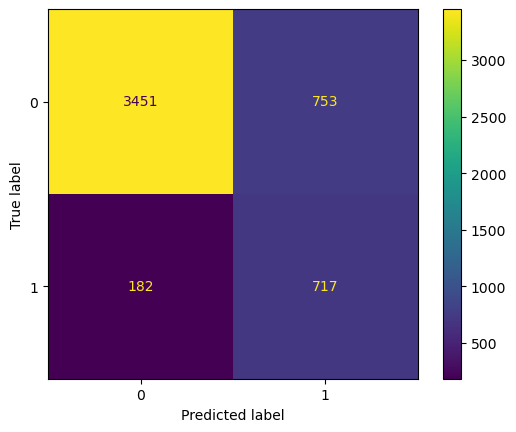

In [46]:
# Confusion matrix

ConfusionMatrixDisplay.from_estimator(model_under, X_test, y_test)

In [47]:
print(classification_report(y_test, model_under.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.82      0.88      4204
           1       0.49      0.80      0.61       899

    accuracy                           0.82      5103
   macro avg       0.72      0.81      0.74      5103
weighted avg       0.87      0.82      0.83      5103



In [48]:
depth=model_under.named_steps["decisiontreeclassifier"].get_depth()
print(depth)

34


<Axes: >

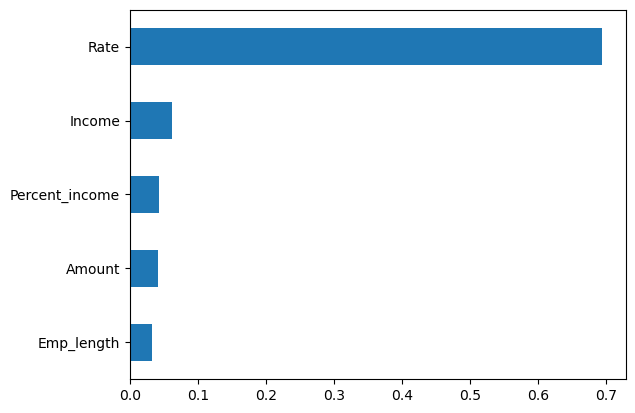

In [49]:
#get impotances and features

features=model_under.named_steps["onehotencoder"].get_feature_names_out()
importances=model_under.named_steps["decisiontreeclassifier"].feature_importances_

# put importances in a series

feat_imp = pd.Series(importances, index=features).sort_values()

#plot series
feat_imp.tail().plot(kind="barh");

Interest rate is the most important among the features under consideration

#SAVE THE MODEL

In [50]:
with open("credit_risk_model_1.pkl", "wb") as f:
    pickle.dump(model_under, f)

In [ ]:
#CREATE A RANDOM FORST MODEL

In [51]:
model_rf= make_pipeline(OneHotEncoder(use_cat_names=True),RandomForestClassifier(random_state=42))
model_rf.fit(X_train_under, y_train_under)

,steps,"[('onehotencoder', ...), ('randomforestclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,verbose,0
,cols,"['Home', 'Intent']"
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,use_cat_names,True


In [52]:
model_rf.score(X_train, y_train)
model_rf.score(X_test, y_test)


0.8042328042328042

Do a parameter tunning for n_estimators and max depth to obtain the best parameters

In [53]:
params={
    "randomforestclassifier__n_estimators": range(25,100,25),
    "randomforestclassifier__max_depth": range(10,100,10)
}
params

{'randomforestclassifier__n_estimators': range(25, 100, 25),
 'randomforestclassifier__max_depth': range(10, 100, 10)}

In [54]:
model=GridSearchCV(
    model_rf,
    param_grid=params,
    cv=5,
    n_jobs=-1,
    verbose=1
)
model


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestclassifier__max_depth': range(10, 100, 10), 'randomforestclassifier__n_estimators': range(25, 100, 25)}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,verbose,0


In [55]:
model.fit(X_train_under, y_train_under)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestclassifier__max_depth': range(10, 100, 10), 'randomforestclassifier__n_estimators': range(25, 100, 25)}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,verbose,0


In [56]:
cv_results=pd.DataFrame(model.cv_results_)
cv_results.head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_randomforestclassifier__max_depth,param_randomforestclassifier__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.647981,0.072830,0.046720,0.008507,10,25,"{'randomforestclassifier__max_depth': 10, 'ran...",0.881787,0.860481,0.854983,0.857045,0.856946,0.862248,0.009928,2
1,1.216669,0.057187,0.066391,0.013552,10,50,"{'randomforestclassifier__max_depth': 10, 'ran...",0.879038,0.860481,0.858419,0.857045,0.856259,0.862248,0.008516,3
2,1.694264,0.085021,0.086439,0.015391,10,75,"{'randomforestclassifier__max_depth': 10, 'ran...",0.882474,0.861168,0.859794,0.854983,0.855571,0.862798,0.010121,1
3,1.036346,0.214400,0.079609,0.023104,20,25,"{'randomforestclassifier__max_depth': 20, 'ran...",0.876289,0.853608,0.853608,0.855670,0.858322,0.859499,0.008571,20
4,1.763119,0.187300,0.086763,0.024506,20,50,"{'randomforestclassifier__max_depth': 20, 'ran...",0.876976,0.854983,0.854983,0.854983,0.856259,0.859637,0.008684,18
5,3.255754,0.182751,0.159767,0.040285,20,75,"{'randomforestclassifier__max_depth': 20, 'ran...",0.879038,0.858419,0.855670,0.855670,0.852132,0.860186,0.009635,11
6,1.230100,0.178192,0.079743,0.023347,30,25,"{'randomforestclassifier__max_depth': 30, 'ran...",0.876976,0.853608,0.849485,0.852234,0.854195,0.857300,0.009972,27
7,2.534310,0.125987,0.141052,0.059651,30,50,"{'randomforestclassifier__max_depth': 30, 'ran...",0.879725,0.857732,0.854983,0.852234,0.853508,0.859636,0.010210,19
8,4.209791,0.096104,0.217768,0.090410,30,75,"{'randomforestclassifier__max_depth': 30, 'ran...",0.883162,0.857732,0.854983,0.852234,0.857634,0.861149,0.011190,4
9,1.671022,0.205110,0.112201,0.035887,40,25,"{'randomforestclassifier__max_depth': 40, 'ran...",0.877663,0.853608,0.851546,0.852234,0.855571,0.858124,0.009866,21


In [57]:
model.best_params_

{'randomforestclassifier__max_depth': 10,
 'randomforestclassifier__n_estimators': 75}

The outcome of our parameter tunning return the best max_depth =10 and n_estimators=75

In [58]:
acc_train=model.score(X_train_over, y_train_over)
acc_test=model.score(X_test, y_test)
probabilities=model.predict_proba(X_test)[:,1]
fpr,tpr,thresholds=roc_curve(y_test, probabilities)
roc_auc= auc(fpr, tpr)
print("Training_accuracy:", round(acc_train, 4))
print("Test_accuracy:", round(acc_test, 4))
print("Area under the curve(AUC):", round(roc_auc, 2))

Training_accuracy: 0.8761
Test_accuracy: 0.8011
Area under the curve(AUC): 0.88


In [59]:
y_test.value_counts()

Default
0    4204
1     899
Name: count, dtype: int64

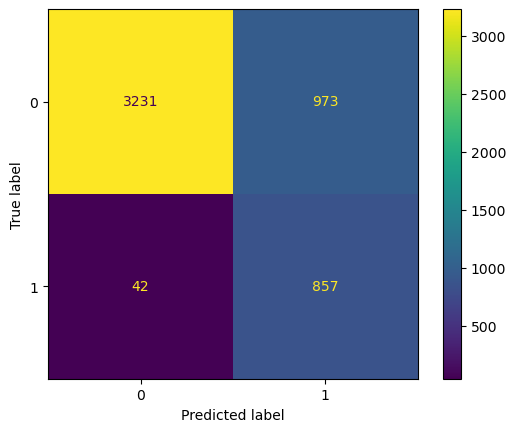

In [60]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)

In [61]:
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.99      0.77      0.86      4204
           1       0.47      0.95      0.63       899

    accuracy                           0.80      5103
   macro avg       0.73      0.86      0.75      5103
weighted avg       0.90      0.80      0.82      5103



Our random forest model gives an accuracy of 80% as against 82% accuracy for the Decision Tree model. However, Its AUC score of 88% means that the random forest is a better classifier. A close look at the classification report also shiws that the random forest model classified 95% of the defaulters correctly with a recall of 0.95.This underscores the fact that accuracy alone is not enough in classification problem especially for an imbalanced data. For this project, we prioritize recall over precision as the cost of incorrectly predicting a defaulter far outweights that of incorrectly predicting a non-defaulter. 

In conclusion Random forest gives the best result so far.

<Axes: >

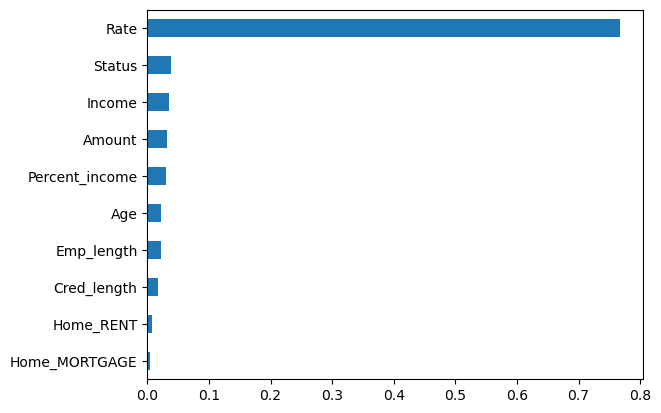

In [62]:
features=model_over.named_steps["onehotencoder"].get_feature_names_out()

importances=model.best_estimator_.named_steps["randomforestclassifier"].feature_importances_

feat_imp=pd.Series(importances, index= features).sort_values()

feat_imp.tail(10).plot(kind="barh")

In [63]:
threshold = 0.4

probabilities = model.predict_proba(X_test)[:,1]
predictions = (probabilities>= threshold).astype(int)
#accuracy = accuracy_score(y_test, predictions)

SAVING OUR BEST MODEL SO FAR

In [64]:
with open("rf_model", "wb") as f:
    pickle.dump(model, f)

In [65]:
with open("cv_model", "rb") as f:
    loaded_model= pickle.load(f)

print(loaded_model)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('onehotencoder',
                                        OneHotEncoder(cols=['Home', 'Intent'],
                                                      use_cat_names=True)),
                                       ('randomforestclassifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'randomforestclassifier__max_depth': range(10, 100, 10),
                         'randomforestclassifier__n_estimators': range(25, 100, 25)},
             verbose=1)


CREATING A GRADIENT BOOSTING CLASSIFIER

In [66]:
model_gb= make_pipeline(OneHotEncoder(use_cat_names=True),GradientBoostingClassifier(random_state=42))
model_gb.fit(X_train_under, y_train_under)

,steps,"[('onehotencoder', ...), ('gradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,verbose,0
,cols,"['Home', 'Intent']"
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,use_cat_names,True


In [67]:
model_gb.score(X_train, y_train)
model_gb.score(X_test, y_test)

0.8105036253184401

PARAMETER TUNNING

In [68]:
params={
    "gradientboostingclassifier__n_estimators": range(25,100,25),
    "gradientboostingclassifier__max_depth": range(10,100,10)
}
params

{'gradientboostingclassifier__n_estimators': range(25, 100, 25),
 'gradientboostingclassifier__max_depth': range(10, 100, 10)}

In [69]:
model_1=GridSearchCV(
    model_gb,
    param_grid=params,
    cv=5,
    n_jobs=-1,
    verbose=1
)
model_1

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'gradientboostingclassifier__max_depth': range(10, 100, 10), 'gradientboostingclassifier__n_estimators': range(25, 100, 25)}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,verbose,0


In [70]:
model_1.fit(X_train_under, y_train_under)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'gradientboostingclassifier__max_depth': range(10, 100, 10), 'gradientboostingclassifier__n_estimators': range(25, 100, 25)}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,verbose,0


In [71]:
model_1.best_params_

{'gradientboostingclassifier__max_depth': 10,
 'gradientboostingclassifier__n_estimators': 25}

In [72]:
model_1.score(X_train, y_train)
model_1.score(X_test, y_test)
probabilities=model_1.predict_proba(X_test)[:,1]
fpr,tpr,thresholds=roc_curve(y_test, probabilities)
roc_auc= auc(fpr, tpr)
print("Training_accuracy:", round(acc_train, 4))
print("Test_accuracy:", round(acc_test, 4))
print("Area under the curve(AUC):", round(roc_auc, 2))

Training_accuracy: 0.8761
Test_accuracy: 0.8011
Area under the curve(AUC): 0.89


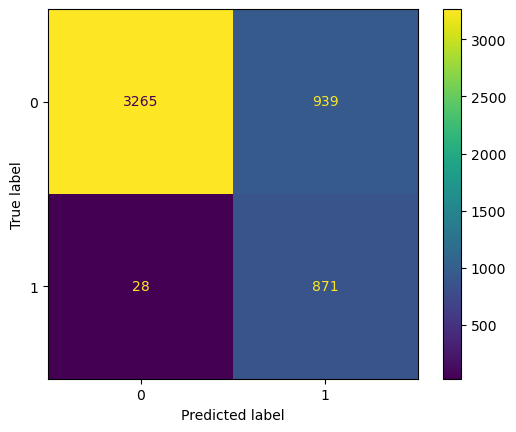

In [73]:
ConfusionMatrixDisplay.from_estimator(model_1, X_test, y_test)

In [74]:
print(classification_report(y_test, model_1.predict(X_test)))

              precision    recall  f1-score   support

           0       0.99      0.78      0.87      4204
           1       0.48      0.97      0.64       899

    accuracy                           0.81      5103
   macro avg       0.74      0.87      0.76      5103
weighted avg       0.90      0.81      0.83      5103



Our gradient boosting model performs slightly better than the random forest classifier with roughly same accuracy of 80% but with a slightly better AUC of 89%. Consequently, 97% of the defaulters were correctly classified. 

This is our BEST MODEL for this project.

In [ ]:
SAVING OUR BEST MODEL

In [75]:
with open("gb_model", "wb") as f:
    pickle.dump(model_1, f)

In [ ]:
PLOTTING THE ROC_CURVE OF THE BEST MODEL

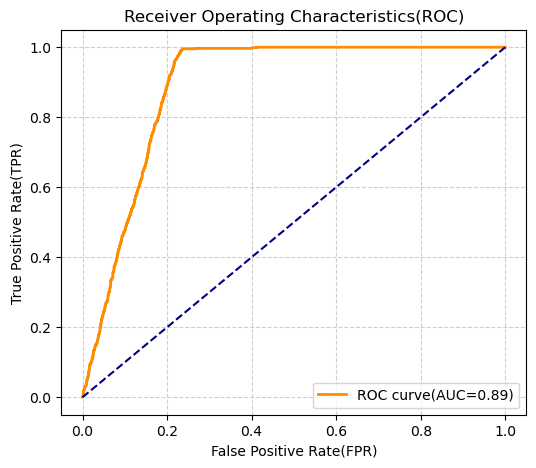

In [76]:
plt.figure(figsize=(6,5))
plt.plot(fpr,tpr,color="darkorange", lw=2, label=f"ROC curve(AUC={roc_auc:.2f})")
plt.plot([0,1], [0,1], color="navy", linestyle="--");
plt.xlabel("False Positive Rate(FPR)")
plt.ylabel("True Positive Rate(TPR)")
plt.title("Receiver Operating Characteristics(ROC)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)